## Week 8: K-Nearest Neighbors

This week I am going to be using k-nearest neighbors to see how the data is clustered near each other. I will be first using the base model to see how it performs and then will hyperparameter tune it to compare the performance. 

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import StandardScaler

In [23]:
model = KNeighborsClassifier()

params = {'n_neighbors' : range(1, 21, 2), 'weights' : ['uniform', 'distance'], 'p' : [1, 2]}

random_search = RandomizedSearchCV(model, params, cv = 5, n_iter = 30)

scaler = StandardScaler()

### Dataset 1: Instacart Dataset

In [24]:
data1 = pd.read_csv('https://raw.githubusercontent.com/eghatzis0527/DX699---HW-Assignments/refs/heads/main/instacart.csv')

transform_cols = ['times_purchased', 'num_orders', 'frequency', 'Product Popularity', 'Last Product Order', 'Last Order', 'Orders Since Last Purchase']

for col in transform_cols:
    data1[f'log_{col}'] = np.log1p(data1[col])

data1_transformed = data1.drop(columns = ['times_purchased', 'num_orders', 'frequency', 'Product Popularity', 'Last Product Order', 'Last Order', 'Orders Since Last Purchase'])

data1_transformed.head()

,user_id,product_id,ordered,log_times_purchased,log_num_orders,log_frequency,log_Product Popularity,log_Last Product Order,log_Last Order,log_Orders Since Last Purchase
0,71,45,0.0,1.791759,3.178054,0.196710,0.005878,2.302585,3.178054,2.708050
1,71,117,1.0,2.995732,3.178054,0.602175,0.001219,3.178054,3.178054,0.000000
2,71,2078,0.0,0.693147,3.178054,0.042560,0.006478,1.386294,3.178054,3.044522
3,71,2825,0.0,1.098612,3.178054,0.083382,0.003743,1.945910,3.178054,2.890372
4,71,3376,1.0,1.098612,3.178054,0.083382,0.003602,2.995732,3.178054,1.609438


In [25]:
X = data1_transformed.drop(columns = ['ordered', 'user_id', 'product_id'])
y = data1_transformed['ordered']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

In [26]:
model.fit(X_train_scaled, y_train)

y_preds = model.predict_proba(X_test_scaled)[:, 1]

values = pd.DataFrame({'Predicted' : y_preds, 'Actual' : y_test})
values['decile'] = pd.qcut(values['Predicted'].rank(method = 'first'), q = 10, labels = False) + 1

lift_table = values.groupby('decile').agg(avg_predicted = ('Predicted', 'mean'), avg_liked = ('Actual', 'mean'))

overall_liked = y_test.mean()

lift_table['lift'] = lift_table['avg_liked']/overall_liked

lift_table['avg_predicted'] = lift_table['avg_predicted'].map(lambda x: f'{x:.3f}')
lift_table['avg_liked'] = lift_table['avg_liked'].map(lambda x: f'{x:.3f}')
lift_table['lift'] = lift_table['lift'].map(lambda x: f'{x:.3f}')

lift_table

,avg_predicted,avg_liked,lift
decile,,,
1,0.000,0.041,0.642
2,0.000,0.040,0.636
3,0.000,0.040,0.626
4,0.000,0.036,0.560
5,0.000,0.043,0.669
6,0.000,0.039,0.616
7,0.000,0.042,0.655
8,0.057,0.059,0.929
9,0.200,0.111,1.740


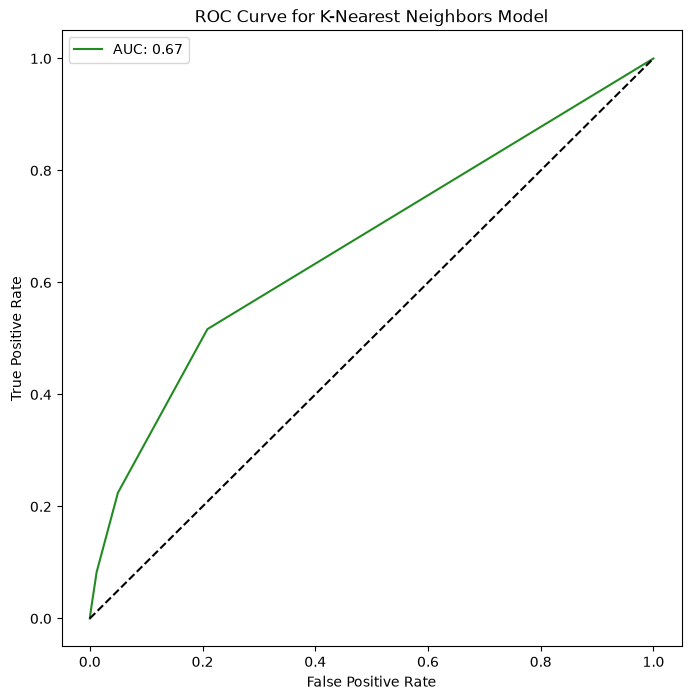

In [27]:
fpr, tpr, thresholds = roc_curve(y_test, y_preds)
roc_auc = auc(fpr, tpr)

plt.figure(figsize = (8, 8))
plt.plot(fpr, tpr, color = 'forestgreen', label = f'AUC: {roc_auc:.2f}')
plt.plot([0,1], [0,1], color = 'black', ls = '--')
plt.title('ROC Curve for K-Nearest Neighbors Model')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()

plt.show()

In [28]:
random_search.fit(X_train, y_train)

print(f'The best hyperparameters for this dataset is {random_search.best_params_}')

The best hyperparameters for this dataset is {'weights': 'uniform', 'p': 1, 'n_neighbors': 19}


In [29]:
best_model = KNeighborsClassifier(weights = 'uniform', p = 1, n_neighbors = 19)

best_model.fit(X_train, y_train)

y_preds = best_model.predict_proba(X_test)[:, 1]

values = pd.DataFrame({'Predicted' : y_preds, 'Actual' : y_test})
values['decile'] = pd.qcut(values['Predicted'].rank(method = 'first'), q = 10, labels = False) + 1

lift_table = values.groupby('decile').agg(avg_predicted = ('Predicted', 'mean'), avg_liked = ('Actual', 'mean'))

overall_liked = y_test.mean()

lift_table['lift'] = lift_table['avg_liked']/overall_liked

lift_table['avg_predicted'] = lift_table['avg_predicted'].map(lambda x: f'{x:.3f}')
lift_table['avg_liked'] = lift_table['avg_liked'].map(lambda x: f'{x:.3f}')
lift_table['lift'] = lift_table['lift'].map(lambda x: f'{x:.3f}')

lift_table

,avg_predicted,avg_liked,lift
decile,,,
1,0.000,0.023,0.359
2,0.000,0.031,0.482
3,0.000,0.021,0.337
4,0.000,0.024,0.378
5,0.000,0.023,0.355
6,0.045,0.044,0.694
7,0.053,0.052,0.823
8,0.083,0.075,1.174
9,0.132,0.108,1.703


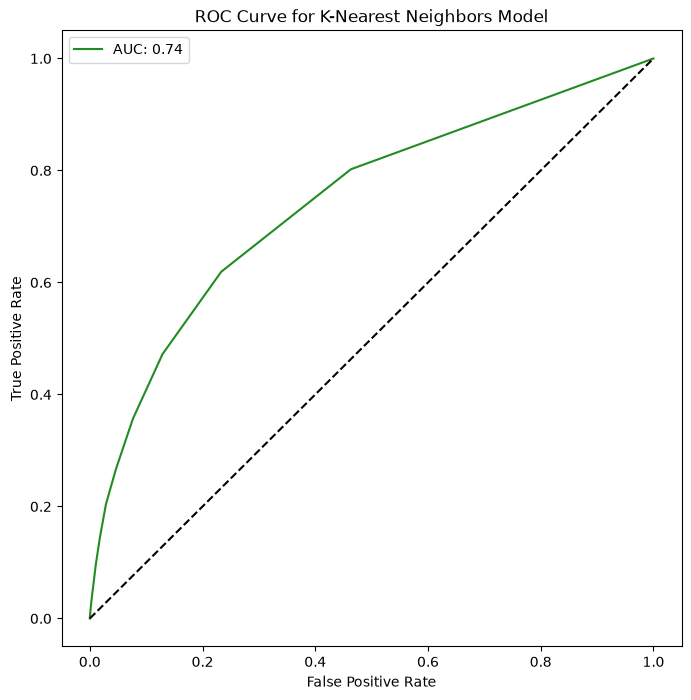

In [30]:
fpr, tpr, thresholds = roc_curve(y_test, y_preds)
roc_auc = auc(fpr, tpr)

plt.figure(figsize = (8, 8))
plt.plot(fpr, tpr, color = 'forestgreen', label = f'AUC: {roc_auc:.2f}')
plt.plot([0,1], [0,1], color = 'black', ls = '--')
plt.title('ROC Curve for K-Nearest Neighbors Model')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()

plt.show()

### Dataset 2: Amazon Reviews Dataset

In [31]:
import ast
from sklearn.preprocessing import MultiLabelBinarizer

small_reviews = pd.read_csv('https://raw.githubusercontent.com/eghatzis0527/DX699---HW-Assignments/refs/heads/main/small_reviews%5B1%5D.csv')

small_meta = pd.read_csv('https://raw.githubusercontent.com/eghatzis0527/DX699---HW-Assignments/refs/heads/main/small_meta%5B1%5D.csv')

small_meta = small_meta.set_index(keys = 'parent_asin')

small_meta = small_meta.drop(columns = ['title', 'images'])

data2 = small_reviews.join(small_meta, on = 'parent_asin', how = 'inner')

data2 = data2.drop(columns = ['main_category', 'store', 'rating_number', 'videos', 'images', 'subtitle', 'author', 'bought_together', 'features', 'description', 'details', 'timestamp', 'text', 'title'])

data2['product_review_count'] = data2.groupby('asin').transform('size')
data2['user_review_count'] = data2.groupby('user_id').transform('size')

data2['price'] = data2['price'].fillna(data2['price'].median())

data2['categories'] = data2['categories'].apply(ast.literal_eval)

mlb = MultiLabelBinarizer()

categories = pd.DataFrame(mlb.fit_transform(data2['categories']), columns = mlb.classes_, index = data2.index)

top_30 = categories.sum().sort_values(ascending = False).head(31).index

categories = categories[top_30[1:31]]

data2 = data2.drop(columns = 'categories')

data2 = data2.join(categories)

columns_to_transform = ['helpful_vote', 'average_rating', 'price', 'product_review_count', 'user_review_count']

for col in columns_to_transform:
    data2[f'log_{col}'] = np.log1p(data2[col])

data2_transformed = data2.drop(columns = ['helpful_vote', 'average_rating', 'price', 'product_review_count', 'user_review_count'])

data2_transformed = data2_transformed.reset_index(drop = True)

for i in range(len(data2_transformed)):
    if data2_transformed.iloc[i]['rating'] == 4:
        data2_transformed.loc[i, 'liked'] = 1
    elif data2_transformed.iloc[i]['rating'] == 5:
        data2_transformed.loc[i, 'liked'] = 1
    else:
        data2_transformed.loc[i, 'liked'] = 0

X = data2_transformed.drop(columns = ['asin', 'parent_asin', 'user_id', 'liked', 'rating'])
y = data2_transformed['liked']

X.head()

,verified_purchase,Beverages,Snacks & Sweets,Pantry Staples,Coffee,Snack Foods,Candy & Chocolate,"Bottled Beverages, Water & Drink Mixes",Cooking & Baking,Breads & Bakery,...,Whole Coffee Beans,"Canned, Jarred & Packaged Foods",Cold Cereals,"Baking Syrups, Sugars & Sweeteners",Black,log_helpful_vote,log_average_rating,log_price,log_product_review_count,log_user_review_count
0,False,1,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0.000000,1.704748,3.257712,0.693147,0.693147
1,True,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,3.295837,1.686399,3.351307,0.693147,0.693147
2,True,1,0,0,1,0,0,0,0,0,...,1,0,0,0,0,0.000000,1.686399,2.889816,0.693147,1.098612
3,True,0,0,1,0,0,0,0,1,0,...,0,0,0,0,0,0.000000,1.722767,2.771964,0.693147,1.098612
4,True,1,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0.000000,1.686399,3.395179,1.609438,0.693147


In [32]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

In [33]:
model.fit(X_train_scaled, y_train)

y_preds = model.predict_proba(X_test_scaled)[:, 1]

values = pd.DataFrame({'Predicted' : y_preds, 'Actual' : y_test})
values['decile'] = pd.qcut(values['Predicted'].rank(method = 'first'), q = 10, labels = False) + 1

lift_table = values.groupby('decile').agg(avg_predicted = ('Predicted', 'mean'), avg_liked = ('Actual', 'mean'))

overall_liked = y_test.mean()

lift_table['lift'] = lift_table['avg_liked']/overall_liked

lift_table['avg_predicted'] = lift_table['avg_predicted'].map(lambda x: f'{x:.3f}')
lift_table['avg_liked'] = lift_table['avg_liked'].map(lambda x: f'{x:.3f}')
lift_table['lift'] = lift_table['lift'].map(lambda x: f'{x:.3f}')

lift_table

,avg_predicted,avg_liked,lift
decile,,,
1,0.627,0.733,0.878
2,0.800,0.867,1.037
3,0.800,0.786,0.940
4,0.800,0.867,1.037
5,0.800,0.929,1.111
6,0.907,0.933,1.117
7,1.000,0.714,0.855
8,1.000,0.867,1.037
9,1.000,0.786,0.940


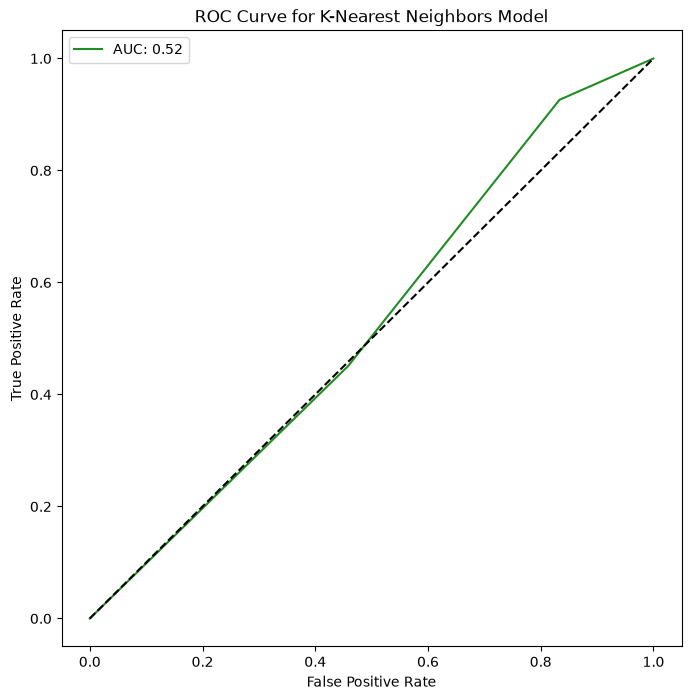

In [34]:
fpr, tpr, thresholds = roc_curve(y_test, y_preds)
roc_auc = auc(fpr, tpr)

plt.figure(figsize = (8, 8))
plt.plot(fpr, tpr, color = 'forestgreen', label = f'AUC: {roc_auc:.2f}')
plt.plot([0,1], [0,1], color = 'black', ls = '--')
plt.title('ROC Curve for K-Nearest Neighbors Model')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()

plt.show()

In [35]:
random_search.fit(X_train, y_train)

print(f'The best hyperparameters for this dataset is {random_search.best_params_}')

The best hyperparameters for this dataset is {'weights': 'uniform', 'p': 2, 'n_neighbors': 11}


In [36]:
best_model = KNeighborsClassifier(weights = 'uniform', p = 2, n_neighbors = 11)

best_model.fit(X_train, y_train)

y_preds = best_model.predict_proba(X_test)[:, 1]

values = pd.DataFrame({'Predicted' : y_preds, 'Actual' : y_test})
values['decile'] = pd.qcut(values['Predicted'].rank(method = 'first'), q = 10, labels = False) + 1

lift_table = values.groupby('decile').agg(avg_predicted = ('Predicted', 'mean'), avg_liked = ('Actual', 'mean'))

overall_liked = y_test.mean()

lift_table['lift'] = lift_table['avg_liked']/overall_liked

lift_table['avg_predicted'] = lift_table['avg_predicted'].map(lambda x: f'{x:.3f}')
lift_table['avg_liked'] = lift_table['avg_liked'].map(lambda x: f'{x:.3f}')
lift_table['lift'] = lift_table['lift'].map(lambda x: f'{x:.3f}')

lift_table

,avg_predicted,avg_liked,lift
decile,,,
1,0.667,0.800,0.957
2,0.776,0.733,0.878
3,0.818,0.929,1.111
4,0.830,0.867,1.037
5,0.909,0.929,1.111
6,0.909,0.667,0.798
7,0.909,0.714,0.855
8,0.909,0.933,1.117
9,1.000,0.786,0.940


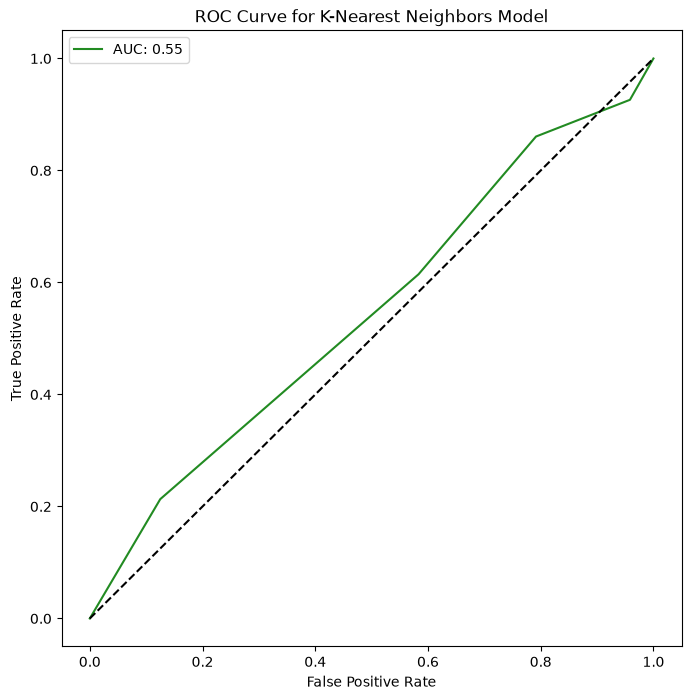

In [37]:
fpr, tpr, thresholds = roc_curve(y_test, y_preds)
roc_auc = auc(fpr, tpr)

plt.figure(figsize = (8, 8))
plt.plot(fpr, tpr, color = 'forestgreen', label = f'AUC: {roc_auc:.2f}')
plt.plot([0,1], [0,1], color = 'black', ls = '--')
plt.title('ROC Curve for K-Nearest Neighbors Model')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()

plt.show()

## Conclusion

Looking at the results, KNN was not the best performing model compared to past models, but it was not the worst performing model I have tried out. For both models, there was an improvement between the base model and the more complex model. For the first dataset, there was a larger jump compared to dataset 2. 

Both models also use the uniform weight as the weighting mechanism, but did use different distance metrics.